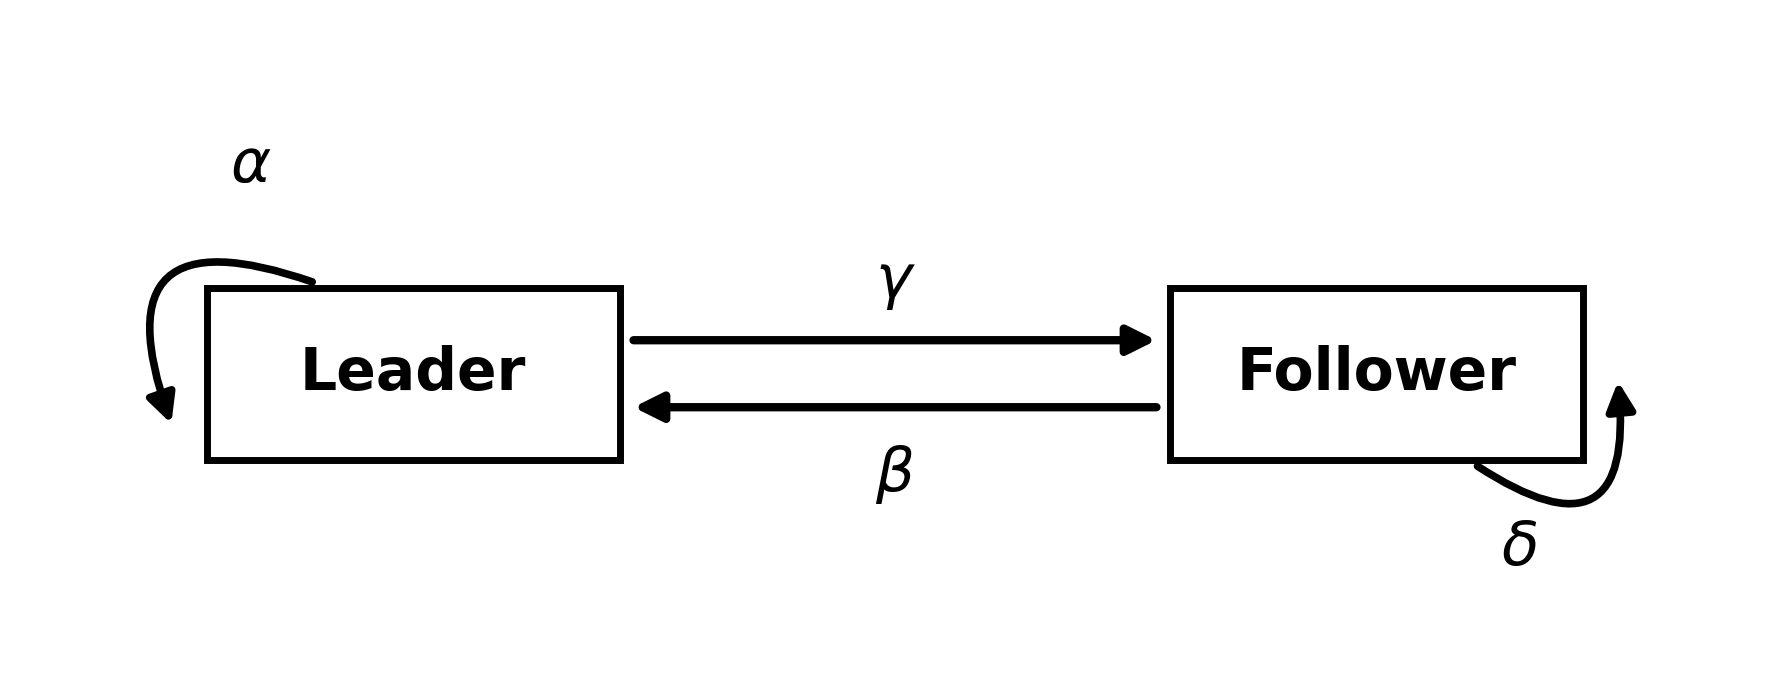

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# ============================================================
# Figure setup
# ============================================================

fig, ax = plt.subplots(figsize=(18, 7))
ax.set_xlim(0, 18)
ax.set_ylim(0, 7)
ax.axis("off")

# ============================================================
# Style
# ============================================================

box_lw = 5
arrow_lw = 6
loop_lw = 5.5
arrow_size = 42
font_box = 42
font_greek = 44

# ============================================================
# Boxes
# ============================================================

leader_x, leader_y = 2.0, 2.3
box_w, box_h = 4.2, 1.8

follower_x, follower_y = 11.8, 2.3

leader_box = Rectangle(
    (leader_x, leader_y),
    box_w,
    box_h,
    fill=False,
    linewidth=box_lw,
    edgecolor="black"
)

follower_box = Rectangle(
    (follower_x, follower_y),
    box_w,
    box_h,
    fill=False,
    linewidth=box_lw,
    edgecolor="black"
)

ax.add_patch(leader_box)
ax.add_patch(follower_box)

ax.text(
    leader_x + box_w/2,
    leader_y + box_h/2,
    "Leader",
    ha="center",
    va="center",
    fontsize=font_box,
    fontweight="bold"
)

ax.text(
    follower_x + box_w/2,
    follower_y + box_h/2,
    "Follower",
    ha="center",
    va="center",
    fontsize=font_box,
    fontweight="bold"
)

# ============================================================
# Straight interaction arrows
# ============================================================

# gamma: Leader -> Follower, slightly above center
gamma_arrow = FancyArrowPatch(
    (leader_x + box_w, leader_y + 1.25),
    (follower_x, follower_y + 1.25),
    arrowstyle="-|>",
    mutation_scale=arrow_size,
    linewidth=arrow_lw,
    color="black",
    shrinkA=10,
    shrinkB=10
)
ax.add_patch(gamma_arrow)

ax.text(
    9.0,
    leader_y + 1.85,
    r"$\gamma$",
    fontsize=font_greek,
    ha="center",
    va="center"
)

# beta: Follower -> Leader, slightly below center
beta_arrow = FancyArrowPatch(
    (follower_x, follower_y + 0.55),
    (leader_x + box_w, leader_y + 0.55),
    arrowstyle="-|>",
    mutation_scale=arrow_size,
    linewidth=arrow_lw,
    color="black",
    shrinkA=10,
    shrinkB=10
)
ax.add_patch(beta_arrow)

ax.text(
    9.0,
    leader_y - 0.15,
    r"$\beta$",
    fontsize=font_greek,
    ha="center",
    va="center"
)

# ============================================================
# Self-loop alpha on Leader
# ============================================================

alpha_loop = FancyArrowPatch(
    (leader_x + 1.1, leader_y + box_h + 0.05),
    (leader_x - 0.35, leader_y + 0.35),
    connectionstyle="arc3,rad=1.05",
    arrowstyle="-|>",
    mutation_scale=arrow_size,
    linewidth=loop_lw,
    color="black"
)
ax.add_patch(alpha_loop)

ax.text(
    leader_x + 0.45,
    leader_y + box_h + 1.1,
    r"$\alpha$",
    fontsize=font_greek,
    ha="center"
)

# ============================================================
# Self-loop delta on Follower
# ============================================================

delta_loop = FancyArrowPatch(
    (follower_x + box_w - 1.1, follower_y - 0.05),
    (follower_x + box_w + 0.35, follower_y + 0.85),
    connectionstyle="arc3,rad=1.05",
    arrowstyle="-|>",
    mutation_scale=arrow_size,
    linewidth=loop_lw,
    color="black"
)
ax.add_patch(delta_loop)

ax.text(
    follower_x + box_w - 0.65,
    follower_y - 1.1,
    r"$\delta$",
    fontsize=font_greek,
    ha="center"
)

plt.tight_layout()

# ============================================================
# Save high quality
# ============================================================

fig.savefig("LeaderFollower_schematic_300dpi.png", dpi=300, bbox_inches="tight")
fig.savefig("LeaderFollower_schematic_600dpi.png", dpi=600, bbox_inches="tight")
fig.savefig("LeaderFollower_schematic.pdf", bbox_inches="tight")
fig.savefig(
    "LeaderFollower_schematic.tiff",
    dpi=600,
    bbox_inches="tight",
    pil_kwargs={"compression": None}
)

plt.show()

/tmp/ipykernel_5958/630834547.py:47: RuntimeWarning: divide by zero encountered in divide
  xstar = -BB / (AA - BB)


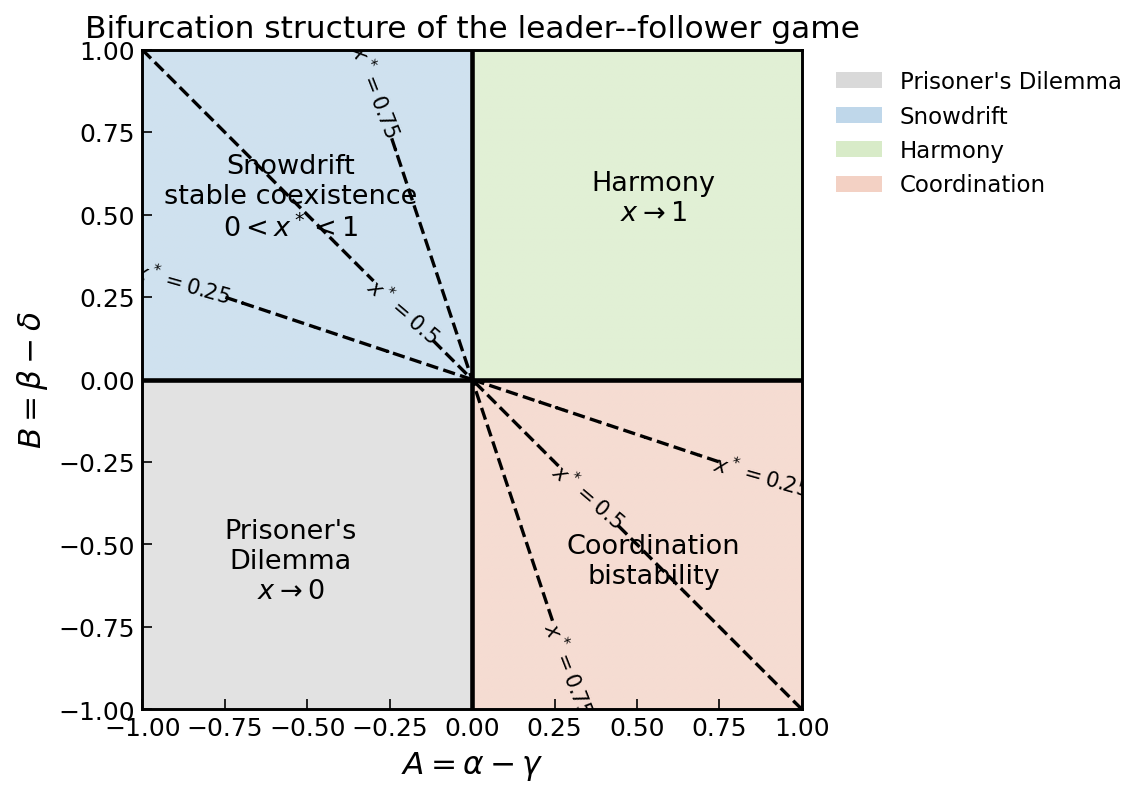

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ============================================================
# Publication-style settings
# ============================================================

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "axes.linewidth": 1.4,
    "lines.linewidth": 2.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 5,
    "ytick.major.size": 5,
    "figure.dpi": 150,
})

# ============================================================
# Bifurcation parameters
# A = alpha - gamma
# B = beta - delta
# ============================================================

A_vals = np.linspace(-1.0, 1.0, 600)
B_vals = np.linspace(-1.0, 1.0, 600)

AA, BB = np.meshgrid(A_vals, B_vals)

# Regime map:
# 0 = PD, 1 = Snowdrift, 2 = Harmony, 3 = Coordination
regime = np.zeros_like(AA)

regime[(AA < 0) & (BB < 0)] = 0   # Prisoner's Dilemma
regime[(AA < 0) & (BB > 0)] = 1   # Snowdrift
regime[(AA > 0) & (BB > 0)] = 2   # Harmony
regime[(AA > 0) & (BB < 0)] = 3   # Coordination

# Interior equilibrium:
# x* = -B / (A - B)
xstar = -BB / (AA - BB)

# Only meaningful when 0 < x* < 1
xstar_masked = np.ma.masked_where((xstar <= 0) | (xstar >= 1), xstar)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

# soft regime colors
colors = [
    "#D9D9D9",  # PD
    "#BFD7EA",  # Snowdrift
    "#D8EBC8",  # Harmony
    "#F3D1C4",  # Coordination
]

cmap = plt.matplotlib.colors.ListedColormap(colors)

ax.imshow(
    regime,
    extent=[A_vals.min(), A_vals.max(), B_vals.min(), B_vals.max()],
    origin="lower",
    cmap=cmap,
    alpha=0.75,
    aspect="auto"
)

# Bifurcation boundaries
ax.axvline(0, color="black", linewidth=2.2)
ax.axhline(0, color="black", linewidth=2.2)

# Interior equilibrium contours
cs = ax.contour(
    AA, BB, xstar_masked,
    levels=[0.25, 0.5, 0.75],
    colors="black",
    linestyles="--",
    linewidths=1.6
)

ax.clabel(
    cs,
    inline=True,
    fontsize=10,
    fmt={0.25: r"$x^*=0.25$", 0.5: r"$x^*=0.5$", 0.75: r"$x^*=0.75$"}
)

# Region labels
ax.text(-0.55, -0.55, "Prisoner's\nDilemma\n$x\\to0$",
        ha="center", va="center", fontsize=13)

ax.text(-0.55, 0.55, "Snowdrift\nstable coexistence\n$0<x^*<1$",
        ha="center", va="center", fontsize=13)

ax.text(0.55, 0.55, "Harmony\n$x\\to1$",
        ha="center", va="center", fontsize=13)

ax.text(0.55, -0.55, "Coordination\nbistability",
        ha="center", va="center", fontsize=13)

# Axis labels
ax.set_xlabel(r"$A=\alpha-\gamma$")
ax.set_ylabel(r"$B=\beta-\delta$")

ax.set_title("Bifurcation structure of the leader--follower game")

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)

ax.set_aspect("equal", adjustable="box")
ax.grid(False)

# Legend
legend_elements = [
    Patch(facecolor=colors[0], edgecolor="none", label="Prisoner's Dilemma"),
    Patch(facecolor=colors[1], edgecolor="none", label="Snowdrift"),
    Patch(facecolor=colors[2], edgecolor="none", label="Harmony"),
    Patch(facecolor=colors[3], edgecolor="none", label="Coordination"),
]

ax.legend(
    handles=legend_elements,
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0)
)

plt.tight_layout()
plt.show()